# Representative days within multiple years

This example keeps the hierarchy **years → days → hours**:

- Three non-leap years: **2021, 2022, 2023**.
- **365 days per year**, with **24 hourly samples per day**.
- Two aligned features: average hourly **demand (MW)** and **solar capacity factor (dimensionless, 0–1)**.
- **20 representative days per year**, giving **60 representative days** in total.

The data are synthetic teaching data, not measured demand or a calibrated solar model. We use UTC to keep every day exactly 24 hours. Vaelchi receives positional arrays; this notebook retains timestamps, feature names, and units alongside them.

Install Vaelchi in the selected notebook kernel environment. Plotting additionally requires `matplotlib`; running a Jupyter kernel requires `ipykernel`. From an authorized checkout, install with `python -m pip install -e . matplotlib ipykernel`.

The example uses `selection="nearest_centroid"` to select observed members of each cluster. It does not change Vaelchi's default selection policy.

In [1]:

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display as display_table

from vaelchi import ahc

HOURS_PER_DAY = 24
DAYS_PER_YEAR = 365
REPRESENTATIVES_PER_YEAR = 20
YEARS = (2021, 2022, 2023)
FEATURE_NAMES = ["demand_mw", "solar_capacity_factor"]
FEATURE_UNITS = ["MW", "1"]
TIMESTEP_HOURS = 1.0

# Display the figures inside Jupyter and the rendered documentation.
%matplotlib inline

## 1. Construct aligned hourly input

Demand varies by hour and season, with a small year-to-year increase and seeded noise. Solar availability is zero at night, with a seasonal factor and one synthetic cloud factor per day. All values within an hourly sample represent that interval's average.

The rows are timestamps and the columns are physical features. Concatenating the years in chronological order lets `parent_length=365` recover the year boundaries.

In [2]:

timestamps = pd.date_range(
    "2021-01-01",
    "2024-01-01",
    freq="h",
    inclusive="left",
    tz="UTC",
)
hour = timestamps.hour.to_numpy()
day_of_year = timestamps.dayofyear.to_numpy()
year = timestamps.year.to_numpy()
rng = np.random.default_rng(20260928)

seasonal = np.cos(2 * np.pi * (day_of_year - 200) / DAYS_PER_YEAR)
daily_demand = 8 * np.cos(2 * np.pi * (hour - 18) / HOURS_PER_DAY)
demand = (
    70
    + 10 * seasonal
    + daily_demand
    + 2 * (year - YEARS[0])
    + rng.normal(0, 1, len(timestamps))
)
daylight = np.maximum(0, np.sin(np.pi * (hour - 6) / 12))
cloud_by_day = rng.uniform(0.4, 1.0, len(timestamps) // HOURS_PER_DAY)
solar = np.clip(
    daylight
    * (0.75 + 0.15 * seasonal)
    * np.repeat(cloud_by_day, HOURS_PER_DAY),
    0,
    1,
)
hourly = pd.DataFrame(
    {"demand_mw": demand, "solar_capacity_factor": solar},
    index=timestamps,
)
hourly.index.name = "timestamp"
np.testing.assert_equal(
    hourly.shape,
    (len(YEARS) * DAYS_PER_YEAR * HOURS_PER_DAY, len(FEATURE_NAMES)),
)
display_table(hourly.head())

,demand_mw,solar_capacity_factor
timestamp,,
2021-01-01 00:00:00+00:00,59.947701,0.0
2021-01-01 01:00:00+00:00,57.599115,0.0
2021-01-01 02:00:00+00:00,57.781611,0.0
2021-01-01 03:00:00+00:00,53.927045,0.0
2021-01-01 04:00:00+00:00,52.840712,0.0


## 2. Select representative days separately within each year

`period_length` counts **hours per day**. `parent_length` counts **days per year**, not hours. `periods` counts **representative days per year**.

For each parent year, Vaelchi standardizes the feature/hour coordinates across that year's days, performs adjacency-constrained Ward clustering, and chooses an observed member nearest each cluster centroid. Clusters cannot cross the parent-year boundary. Standardization is internal; returned demand and solar profiles retain their original units.

In [3]:

result = ahc(
    hourly["demand_mw"].to_numpy(),
    hourly["solar_capacity_factor"].to_numpy(),
    period_length=HOURS_PER_DAY,
    parent_length=DAYS_PER_YEAR,
    periods=REPRESENTATIVES_PER_YEAR,
    selection="nearest_centroid",
)
expected_representatives = len(YEARS) * REPRESENTATIVES_PER_YEAR
np.testing.assert_equal(
    result.representatives.shape,
    (expected_representatives, HOURS_PER_DAY, len(FEATURE_NAMES)),
)
print("Representative profiles:", result.representatives.shape)
print("Original-day mappings:", result.labels.shape)
print("Days represented:", int(result.weights.sum()))

Representative profiles: (60, 24, 2)
Original-day mappings: (1095,)
Days represented: 1095


The expected shapes are `(60, 24, 2)` for representative profiles and `(1095,)` for original-day mappings. The two feature columns remain in input order: demand, then solar.

## 3. Attach calendar dates and inspect weights

`representative_indices` gives selected **original day positions across all years**. `labels` gives **rows of the representative array**, not original day positions. Both are zero-based.

A weight is a count of original days represented by one selected day. A representative with weight 12 represents 12 days, or 288 hourly intervals here.

In [4]:

original_day_dates = hourly.index[::HOURS_PER_DAY]
representative_dates = original_day_dates[result.representative_indices]
representative_table = pd.DataFrame(
    {
        "representative_row": np.arange(expected_representatives),
        "year": representative_dates.year,
        "selected_date": representative_dates,
        "original_day_index": result.representative_indices,
        "weight_days": result.weights,
        "represented_hours": result.weights * HOURS_PER_DAY,
    },
)
yearly_summary = representative_table.groupby("year").agg(
    representative_days=("representative_row", "size"),
    original_days=("weight_days", "sum"),
    represented_hours=("represented_hours", "sum"),
)
np.testing.assert_array_equal(yearly_summary.index.to_numpy(), YEARS)
np.testing.assert_array_equal(
    yearly_summary["representative_days"],
    np.full(len(YEARS), REPRESENTATIVES_PER_YEAR),
)
np.testing.assert_array_equal(
    yearly_summary["original_days"],
    np.full(len(YEARS), DAYS_PER_YEAR),
)
display_table(yearly_summary)
display_table(representative_table.head())

,representative_days,original_days,represented_hours
year,,,
2021,20,365,8760
2022,20,365,8760
2023,20,365,8760


,representative_row,year,selected_date,original_day_index,weight_days,represented_hours
0,0,2021,2021-02-17 00:00:00+00:00,47,66,1584
1,1,2021,2021-03-14 00:00:00+00:00,72,15,360
2,2,2021,2021-03-31 00:00:00+00:00,89,11,264
3,3,2021,2021-04-05 00:00:00+00:00,94,8,192
4,4,2021,2021-04-18 00:00:00+00:00,107,12,288


Each year should have **20 representative days**, weights summing to **365 days**, and **8,760 represented hours**. No individual hourly value is multiplied by its day weight when reconstructing chronology: the mapping repeats the entire selected daily profile at the appropriate original day positions.

In [5]:

day_mapping = pd.DataFrame(
    {
        "original_date": original_day_dates,
        "year": original_day_dates.year,
        "representative_row": result.labels,
        "selected_date": representative_dates[result.labels],
    },
)
# Verify that every original day maps to a representative from the same year.
np.testing.assert_array_equal(
    representative_dates.year.to_numpy()[result.labels],
    original_day_dates.year.to_numpy(),
)
np.testing.assert_array_equal(
    np.bincount(result.labels, minlength=expected_representatives),
    result.weights,
)
# Nearest-centroid representatives must belong to their own clusters.
np.testing.assert_array_equal(
    result.labels[result.representative_indices],
    np.arange(expected_representatives),
)
original_profiles = hourly.to_numpy().reshape(
    -1,
    HOURS_PER_DAY,
    len(FEATURE_NAMES),
)
np.testing.assert_array_equal(
    result.representatives,
    original_profiles[result.representative_indices],
)
display_table(day_mapping.groupby("year").head(3))

,original_date,year,representative_row,selected_date
0,2021-01-01 00:00:00+00:00,2021,0,2021-02-17 00:00:00+00:00
1,2021-01-02 00:00:00+00:00,2021,0,2021-02-17 00:00:00+00:00
2,2021-01-03 00:00:00+00:00,2021,0,2021-02-17 00:00:00+00:00
365,2022-01-01 00:00:00+00:00,2022,20,2022-01-02 00:00:00+00:00
366,2022-01-02 00:00:00+00:00,2022,20,2022-01-02 00:00:00+00:00
367,2022-01-03 00:00:00+00:00,2022,20,2022-01-02 00:00:00+00:00
730,2023-01-01 00:00:00+00:00,2023,40,2023-01-13 00:00:00+00:00
731,2023-01-02 00:00:00+00:00,2023,40,2023-01-13 00:00:00+00:00
732,2023-01-03 00:00:00+00:00,2023,40,2023-01-13 00:00:00+00:00


## 4. Visualize the selected profiles

Each curve is one observed representative day for the first year. The labels retain physical units. Curve count is 20, while each curve's associated weight may differ.

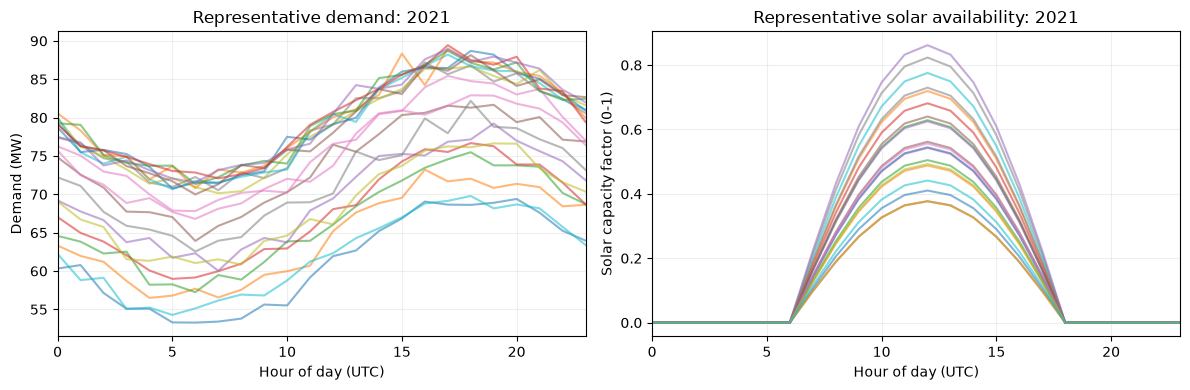

In [6]:

first_year_rows = np.flatnonzero(representative_dates.year == YEARS[0])
hours = np.arange(HOURS_PER_DAY)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(
    hours,
    result.representatives[first_year_rows, :, 0].T,
    alpha=0.55,
)
axes[1].plot(
    hours,
    result.representatives[first_year_rows, :, 1].T,
    alpha=0.55,
)
axes[0].set(ylabel="Demand (MW)", title=f"Representative demand: {YEARS[0]}")
axes[1].set(
    ylabel="Solar capacity factor (0-1)",
    title=f"Representative solar availability: {YEARS[0]}",
)
for axis in axes:
    axis.set_xlabel("Hour of day (UTC)")
    axis.set_xlim(0, HOURS_PER_DAY - 1)
    axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 5. Reconstruct the original hourly chronology

`reconstruct()` follows the labels and expands the representatives into `(26280, 2)` hourly values. It approximates the original data; it does not recover the discarded detail.

The following plot compares the first week of the first year. The timestamp index comes from this notebook, because Vaelchi does not store calendar metadata.

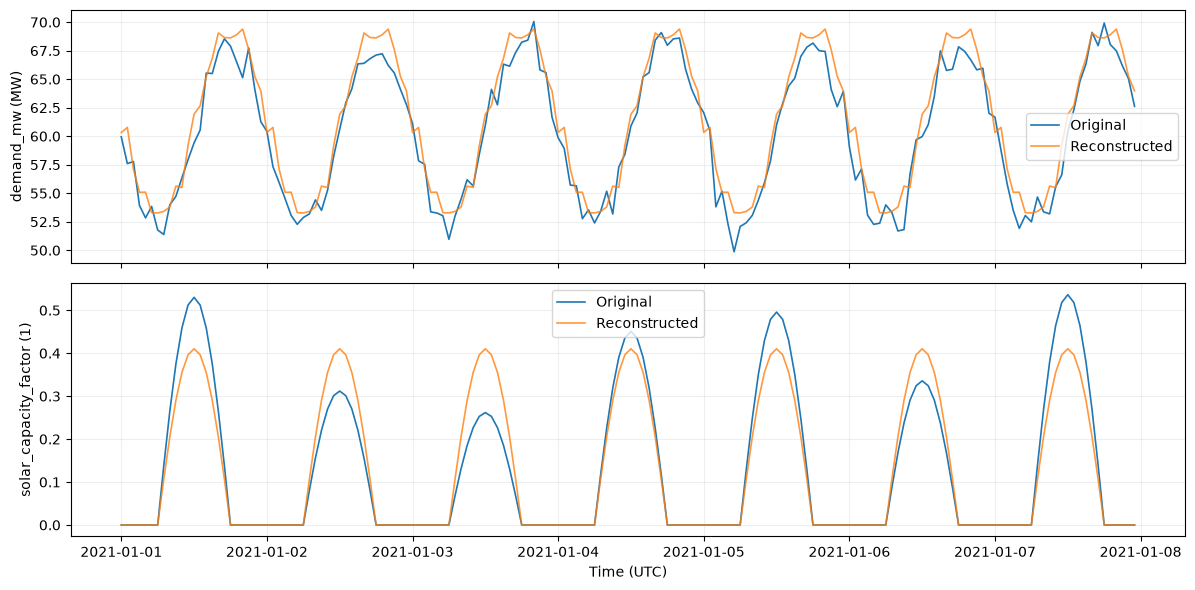

In [7]:

reconstructed = pd.DataFrame(
    result.reconstruct(),
    index=hourly.index,
    columns=FEATURE_NAMES,
)
np.testing.assert_equal(reconstructed.shape, hourly.shape)
first_week = slice(0, 7 * HOURS_PER_DAY)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for axis, feature, unit in zip(axes, FEATURE_NAMES, FEATURE_UNITS):
    axis.plot(
        hourly.index[first_week],
        hourly[feature].iloc[first_week],
        label="Original",
        linewidth=1.2,
    )
    axis.plot(
        reconstructed.index[first_week],
        reconstructed[feature].iloc[first_week],
        label="Reconstructed",
        linewidth=1.2,
        alpha=0.8,
    )
    axis.set_ylabel(f"{feature} ({unit})")
    axis.legend()
    axis.grid(alpha=0.2)
axes[-1].set_xlabel("Time (UTC)")
fig.tight_layout()
plt.show()

## 6. Use weights for annual energy accounting

For hourly average demand in MW, daily energy is the sum of the 24 values multiplied by **1 hour**. Multiply each representative day's energy by its **day count**, then sum within its year.

This weighted energy equals the reconstructed series' energy. It need not equal the original series' energy: selecting observed days does not impose energy preservation. The table reports that approximation error explicitly. The solar feature is a capacity factor, so converting it into generated energy would additionally require a specified generation capacity.

In [8]:

representative_energy = representative_table.assign(
    weighted_demand_mwh=(
        result.representatives[:, :, 0].sum(axis=1)
        * TIMESTEP_HOURS
        * result.weights
    ),
)
energy_comparison = pd.DataFrame(
    {
        "original_mwh": (
            hourly["demand_mw"].groupby(hourly.index.year).sum()
            * TIMESTEP_HOURS
        ),
        "representative_mwh": (
            representative_energy.groupby("year")["weighted_demand_mwh"].sum()
        ),
    },
)
energy_comparison["relative_error_percent"] = 100 * (
    energy_comparison["representative_mwh"] / energy_comparison["original_mwh"]
    - 1
)
reconstructed_energy = (
    reconstructed["demand_mw"].groupby(reconstructed.index.year).sum()
    * TIMESTEP_HOURS
)
# Different summation groupings may differ by floating-point roundoff.
np.testing.assert_allclose(
    energy_comparison["representative_mwh"],
    reconstructed_energy,
    rtol=1e-12,
    atol=1e-8,
)
display_table(energy_comparison)

,original_mwh,representative_mwh,relative_error_percent
2021,613090.002791,615482.521747,0.390239
2022,630779.006976,629676.323552,-0.174813
2023,648211.012327,648010.777084,-0.030890


## 7. Export a framework-independent result

`to_dict()` contains ordinary lists and scalars. The surrounding export adds feature units and calendar metadata maintained by this example. An application can map the two columns to its own components and use the day weights in its reduced model.

The round-trip check below uses only the exported arrays and labels to reconstruct exactly the same approximation. No file is written by this example.

In [9]:

export = {
    "feature_names": FEATURE_NAMES,
    "feature_units": FEATURE_UNITS,
    "timestep_hours": TIMESTEP_HOURS,
    "period_length": HOURS_PER_DAY,
    "original_day_dates": original_day_dates.strftime("%Y-%m-%d").tolist(),
    "representative_dates": representative_dates.strftime("%Y-%m-%d").tolist(),
    "clustering": result.to_dict(),
}
export_json = json.dumps(export, allow_nan=False)
decoded = json.loads(export_json)
payload = decoded["clustering"]
profiles = np.asarray(payload["representatives"])
from_export = profiles[payload["labels"]].reshape(-1, len(FEATURE_NAMES))
np.testing.assert_array_equal(from_export, reconstructed.to_numpy())
print("Exported representative shape:", profiles.shape)
print("JSON round-trip reproduces the reconstructed hourly series exactly.")

Exported representative shape: (60, 24, 2)
JSON round-trip reproduces the reconstructed hourly series exactly.


## Calendar variations and a shared multi-year set

- **Leap years:** a single `parent_length` requires equal-sized parents. Split real data by calendar year and call `ahc` on each year separately, omitting `parent_length` for each call. A complete hourly leap year has 366 days. Preserve the year with each result and adjust row/day offsets if combining their mappings.
- **Daylight saving and missing hours:** this example uses complete UTC days. Real input must be aligned to a deliberate time convention with complete equal-length daily profiles before calling Vaelchi; missing or duplicated local hours cannot be silently reshaped as 24-hour days.
- **One shared set across years:** omitting `parent_length` from the combined input selects 20 representatives for all three years together. It permits clusters to cross year boundaries and standardizes over the combined parent.
- **Temporal hierarchy:** this call reduces days while retaining all 24 hours within each selected day. It does not also reduce the hours or cluster the years.
